#### importing

In [1]:
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torch

In [2]:
words = open('../names.txt', 'r').read().splitlines()

#### constructing the data

In [3]:
vocab_size = 27

letters = sorted(list(set(''.join(words))))
str_to_int = {s:i+1 for i, s in enumerate(letters)}
str_to_int['.'] = 0
int_to_str = {i:s for s, i in str_to_int.items()}


In [ ]:
context_length = 3

def build_dataset(words):   
    X, Y = [], []

    for word in words:
        context = [0] * context_length
        for character in word + '.':
            index = str_to_int[character]
            Y.append(index)
            X.append(context)
            context = context[1:] + [index]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(1234)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtrain, Ytrain = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[:n2])


#### Parameters

In [7]:
emb_dim = 10 
n_hidden = 300

g = torch.Generator().manual_seed(6710)
C  = torch.randn((vocab_size, emb_dim),                generator=g)
W1 = torch.randn((context_length * emb_dim, n_hidden), generator=g)
b1 = torch.rand(n_hidden,                              generator=g)
W2 = torch.randn((n_hidden, vocab_size),               generator=g)
b2 = torch.rand(vocab_size,                            generator=g)

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters), 'parameters')
for p in parameters:
    p.requires_grad = True

17697 parameters


#### training the net

In [ ]:
max_steps = 200_000
batch_size = 50
loss_list = []

for k in range(max_steps):

    #minibatch
    index = torch.randint(0, Xtrain.shape[0], (batch_size,), generator=g)

    # Forward
    embeddings = C[Xtrain[index]]
    h = torch.tanh(embeddings.view(-1, context_length * emb_dim) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytrain[index])

    #Backward
    for p in parameters:
        p.grad = None
    loss.backward()

    #Update
    #lr =lrs[k]
    step_size = 0.1 if k < 100_000 else 0.01
    for p in parameters:
        p.data += -step_size * p.grad

    if k % 10_000 == 0:
        print(f"{k:7d}/{max_steps}: {loss.item():.4f}")
    loss_list.append(loss.log10().item())

    

      0/200000: 31.4048
  10000/200000: 2.6027
  20000/200000: 2.2297
  30000/200000: 2.2691
  40000/200000: 2.8524
  50000/200000: 2.4641
  60000/200000: 2.2784
  70000/200000: 2.5798
  80000/200000: 2.3294
  90000/200000: 2.5915
 100000/200000: 2.3079
 110000/200000: 2.2328
 120000/200000: 2.4392
 130000/200000: 1.9419
 140000/200000: 1.7307
 150000/200000: 1.8644
 160000/200000: 1.9812
 170000/200000: 2.1353
 180000/200000: 2.1906
 190000/200000: 2.0354


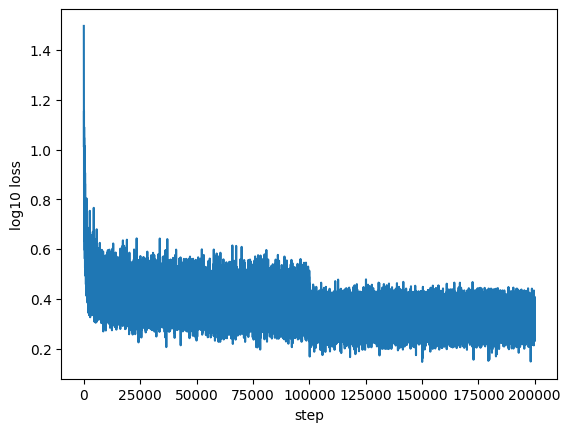

In [9]:
plt.plot(loss_list)
plt.xlabel('step'); plt.ylabel('log10 loss');

#### Validation Loss

In [10]:
embedding = C[Xval]
h = torch.tanh(embedding.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yval)
loss

tensor(2.1686, grad_fn=<NllLossBackward0>)

#### Generations

In [11]:
g = torch.Generator().manual_seed(5324)

for i in range(10):
    out = []
    context = [0] * context_length
    while True:
        embeddings = C[context]
        h = torch.tanh(embeddings.view(1, -1) @ W1 + b1) #1 as size of set dealing with, here one example at time
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        index = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [index]
        out.append(index)
        if index == 0:
            break
    print(''.join(int_to_str[i] for i in out))
        
    

ahieann.
sadalina.
tayna.
joaa.
irilynna.
payzly.
jare.
beystexlyna.
dalani.
ash.


#### embedding visualisation

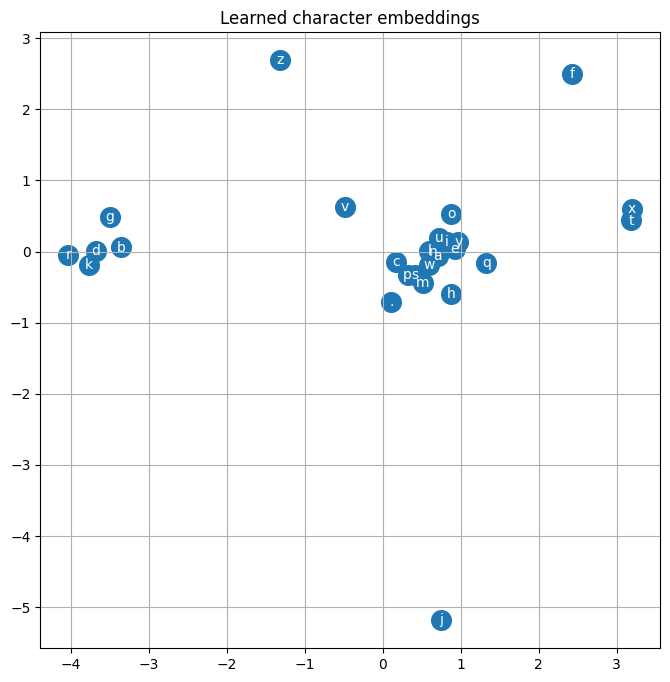

In [14]:
with torch.no_grad():
    C_centered = C - C.mean(0)
    U, S, V = torch.pca_lowrank(C_centered, q=2)
    C2 = C_centered @ V

plt.figure(figsize=(8, 8))
plt.scatter(C2[:, 0], C2[:, 1], s=200)
for i in range(vocab_size):
    plt.text(C2[i, 0].item(), C2[i, 1].item(), int_to_str[i], ha='center', va='center', color='white')
plt.grid(True)
plt.title('Learned character embeddings');